# APTOS Blindness Detection: ResNet50 Fine-Tuning

This notebook trains a five-class diabetic-retinopathy classifier on the balanced training split created by `Dataset/data_augmentation.ipynb`. The original 512x512 RGB CLAHE preprocessing artifacts are inspected before model code is created, and validation remains the original held-out split.

## Cell 1 - Environment and Imports

In [16]:
from pathlib import Path
import json
import os
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE
IMAGE_SIZE = (224, 224)
NUM_CLASSES = 5
BATCH_SIZE = 32
print('TensorFlow:', tf.__version__)
print('Visible GPUs:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
Visible GPUs: []


## Cell 2 - Inspect Preprocessing and Load Data

In [11]:
# Locate both the original preprocessing artifacts and the augmented split.
DATASET_CANDIDATES = [
    Path('Dataset/APTOS_preprocessed_512_CLAHE/preprocessed_aptos_512_clahe'),
    Path('../Dataset/APTOS_preprocessed_512_CLAHE/preprocessed_aptos_512_clahe'),
]
DATASET_ROOT = next((path.resolve() for path in DATASET_CANDIDATES if path.exists()), None)
if DATASET_ROOT is None:
    raise FileNotFoundError('Could not locate the preprocessed APTOS dataset.')

BALANCED_CANDIDATES = [
    Path('Dataset/aptos_512_clahe_balanced'),
    Path('../Dataset/aptos_512_clahe_balanced'),
    Path('aptos_512_clahe_balanced'),
]
BALANCED_ROOT = next((path.resolve() for path in BALANCED_CANDIDATES if path.exists()), None)
if BALANCED_ROOT is None:
    raise FileNotFoundError(
        'Could not locate the augmented dataset. Run Dataset/data_augmentation.ipynb first.'
    )

REPORT_PATH = DATASET_ROOT / 'preprocessing_report.json'
MANIFEST_PATH = DATASET_ROOT / 'image_manifest.csv'
README_PATH = DATASET_ROOT / 'README.txt'
BALANCED_TRAIN_CSV_PATH = BALANCED_ROOT / 'train' / 'labels.csv'
BALANCED_VAL_CSV_PATH = BALANCED_ROOT / 'validation' / 'labels.csv'

with REPORT_PATH.open(encoding='utf-8') as file:
    preprocessing_report = json.load(file)
readme_text = README_PATH.read_text(encoding='utf-8')
manifest = pd.read_csv(MANIFEST_PATH)
train_df = pd.read_csv(BALANCED_TRAIN_CSV_PATH)
val_split = pd.read_csv(BALANCED_VAL_CSV_PATH)

print('Original dataset root:', DATASET_ROOT)
print('Balanced dataset root:', BALANCED_ROOT)
print('README:\n', readme_text)
print('Preprocessing report:')
display(pd.json_normalize(preprocessing_report).T.rename(columns={0: 'value'}))
print('Manifest preview:')
display(manifest.head())

assert preprocessing_report['target_size'] == [512, 512]
assert preprocessing_report['color_mode'] == 'RGB'
assert preprocessing_report['normalization'].startswith('not applied')
assert preprocessing_report['clahe']['applied'] is True
assert set(manifest['output_mode'].dropna()) == {'RGB'}
assert set(manifest['variant'].dropna()) == {'clahe'}

for frame, split_name in ((train_df, 'train'), (val_split, 'validation')):
    frame['diagnosis'] = frame['diagnosis'].astype('int32')
    frame['image_path'] = frame['id_code'].map(
        lambda image_id: str(BALANCED_ROOT / split_name / 'images' / f'{image_id}.png')
    )
    missing_images = frame.loc[~frame['image_path'].map(os.path.exists)]
    if not missing_images.empty:
        raise FileNotFoundError(
            f'Missing {split_name} images: {missing_images.head()}'
        )

train_split = train_df
print(f'Train images: {len(train_split):,}; validation images: {len(val_split):,}')
display(train_split['diagnosis'].value_counts().sort_index().rename('train_count').to_frame())
display(val_split['diagnosis'].value_counts().sort_index().rename('validation_count').to_frame())

Original dataset root: /media/amin/data/Machine-Learning-Engineer/11-Samsung Innovation Campus/SIC Ai Itern/45- Presentation 3/Dataset/APTOS_preprocessed_512_CLAHE/preprocessed_aptos_512_clahe
Balanced dataset root: /media/amin/data/Machine-Learning-Engineer/11-Samsung Innovation Campus/SIC Ai Itern/45- Presentation 3/Dataset/aptos_512_clahe_balanced
README:
 APTOS CLAHE VARIANT

Variant: clahe
Output: RGB PNG, 512x512
The source images are not modified. Aspect ratio is preserved and centered black padding is used.
This is an experimental preprocessing variant, not a claim of improved accuracy.
Compare with the baseline using the same validation split and metrics.

Preprocessing report:


,value
created_utc,2026-10-26T00:54:20.978174+00:00
dataset,APTOS 2019 Blindness Detection
variant,clahe
target_size,"[512, 512]"
format,PNG
color_mode,RGB
resize,Lanczos; preserve aspect ratio; centered black...
orientation,EXIF transpose if available
cropping,not applied
normalization,not applied; PNG channel values remain 0-255


Manifest preview:


,split,id_code,diagnosis,source_file,output_file,output_width,output_height,output_mode,variant
0,train,000c1434d8d7,2.0,train_images\000c1434d8d7.png,train_images\000c1434d8d7.png,512,512,RGB,clahe
1,train,001639a390f0,4.0,train_images\001639a390f0.png,train_images\001639a390f0.png,512,512,RGB,clahe
2,train,0024cdab0c1e,1.0,train_images\0024cdab0c1e.png,train_images\0024cdab0c1e.png,512,512,RGB,clahe
3,train,002c21358ce6,0.0,train_images\002c21358ce6.png,train_images\002c21358ce6.png,512,512,RGB,clahe
4,train,005b95c28852,0.0,train_images\005b95c28852.png,train_images\005b95c28852.png,512,512,RGB,clahe


Train images: 6,315; validation images: 550


,train_count
diagnosis,
0,1263
1,1263
2,1263
3,1263
4,1263


,validation_count
diagnosis,
0,271
1,56
2,150
3,29
4,44


## Cell 3 - TensorFlow Data Pipeline

In [12]:
def decode_and_resize(path, label, training=False):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_png(image_bytes, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE, method='lanczos3')
    image = tf.cast(image, tf.float32)
    if training:
        image = tf.image.random_flip_left_right(image, seed=SEED)
        image = tf.image.random_brightness(image, max_delta=8.0, seed=SEED)
        image = tf.clip_by_value(image, 0.0, 255.0)
    image = preprocess_input(image)
    return image, tf.one_hot(label, depth=NUM_CLASSES)

def make_dataset(frame, training=False):
    paths = frame['image_path'].to_numpy(dtype=str)
    labels = frame['diagnosis'].to_numpy(dtype=np.int32)
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        dataset = dataset.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    return (dataset
            .map(lambda path, label: decode_and_resize(path, label, training), num_parallel_calls=AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(AUTOTUNE))

train_ds = make_dataset(train_split, training=True)
val_ds = make_dataset(val_split, training=False)

class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=train_split['diagnosis'],
)
CLASS_WEIGHTS = dict(enumerate(class_weights_array.astype('float32')))
print('Class weights:', CLASS_WEIGHTS)

sample_images, sample_labels = next(iter(train_ds))
print('Batch shape:', sample_images.shape, 'Label shape:', sample_labels.shape)
assert sample_images.shape[1:] == (224, 224, 3)
assert sample_labels.shape[1] == NUM_CLASSES

Class weights: {0: 1.0, 1: 1.0, 2: 1.0, 3: 1.0, 4: 1.0}
Batch shape: (32, 224, 224, 3) Label shape: (32, 5)


## Cell 4 - ResNet50 Architecture

In [13]:
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(*IMAGE_SIZE, 3),
)
base_model.trainable = False

inputs = keras.Input(shape=(*IMAGE_SIZE, 3), name='image')
features = base_model(inputs, training=False)
features = layers.GlobalAveragePooling2D(name='global_average_pooling')(features)
features = layers.Dropout(0.30, name='dropout')(features)
outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='severity')(features)
model = keras.Model(inputs, outputs, name='aptos_resnet50')
model.summary()

Model: "aptos_resnet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ severity (Dense)                │ (None, 5)              │        10,245 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,597,957 (90.02 MB)

 Trainable params: 10,245 (40.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

## Cell 5 - Compilation and Callbacks

In [14]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
    metrics=[keras.metrics.CategoricalAccuracy(name='accuracy')],
)

CHECKPOINT_PATH = str(BALANCED_ROOT.parent / 'resnet50_aptos_balanced_best.keras')
callbacks = [
    keras.callbacks.ModelCheckpoint(
        CHECKPOINT_PATH, monitor='val_accuracy', mode='max',
        save_best_only=True, verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy', mode='max', patience=5,
        restore_best_weights=True, verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.2, patience=2,
        min_lr=1e-7, verbose=1,
    ),
]
print('Trainable parameters:', sum(np.prod(variable.shape) for variable in model.trainable_variables))
print('Checkpoint:', CHECKPOINT_PATH)

Trainable parameters: 10245
Checkpoint: /media/amin/data/Machine-Learning-Engineer/11-Samsung Innovation Campus/SIC Ai Itern/45- Presentation 3/Dataset/resnet50_aptos_balanced_best.keras


## Cell 6 - Training and Evaluation

Epoch 1/20
198/198 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.2573 - loss: 1.9429
Epoch 1: val_accuracy improved from None to 0.62364, saving model to /media/amin/data/Machine-Learning-Engineer/11-Samsung Innovation Campus/SIC Ai Itern/45- Presentation 3/Dataset/resnet50_aptos_balanced_best.keras
198/198 ━━━━━━━━━━━━━━━━━━━━ 311s 2s/step - accuracy: 0.3218 - loss: 1.7011 - val_accuracy: 0.6236 - val_loss: 1.0563 - learning_rate: 1.0000e-04
Epoch 2/20
198/198 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4406 - loss: 1.4122
Epoch 2: val_accuracy improved from 0.62364 to 0.68545, saving model to /media/amin/data/Machine-Learning-Engineer/11-Samsung Innovation Campus/SIC Ai Itern/45- Presentation 3/Dataset/resnet50_aptos_balanced_best.keras
198/198 ━━━━━━━━━━━━━━━━━━━━ 320s 2s/step - accuracy: 0.4600 - loss: 1.3695 - val_accuracy: 0.6855 - val_loss: 0.9310 - learning_rate: 1.0000e-04
Epoch 3/20
198/198 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4986 - loss: 1.2760
Epoch 3: val_accur

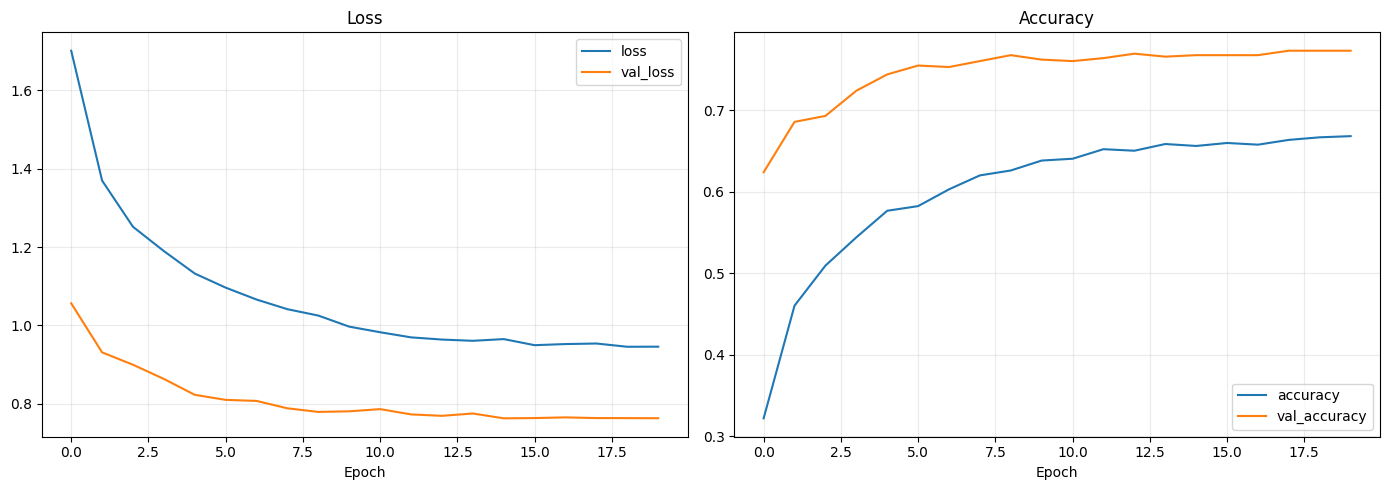

In [15]:
EPOCHS = 20
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=CLASS_WEIGHTS,
    callbacks=callbacks,
)

evaluation = model.evaluate(val_ds, return_dict=True, verbose=1)
print('Validation metrics:', evaluation)

history_df = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
history_df[['loss', 'val_loss']].plot(ax=axes[0], title='Loss')
history_df[['accuracy', 'val_accuracy']].plot(ax=axes[1], title='Accuracy')
for axis in axes:
    axis.set_xlabel('Epoch')
    axis.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Optional second stage after the frozen-head baseline has converged.
# Unfreeze only the final ResNet block and recompile with a smaller rate.
# for layer in base_model.layers[-30:]:
#     layer.trainable = True
# model.compile(optimizer=keras.optimizers.Adam(1e-5),
#               loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
#               metrics=[keras.metrics.CategoricalAccuracy(name='accuracy')])
# fine_tune_history = model.fit(train_ds, validation_data=val_ds, epochs=10,
#                               class_weight=CLASS_WEIGHTS, callbacks=callbacks)

In [18]:
model.save('resnet50_aptos_complete_model.keras')
print('Model saved successfully!')

Model saved successfully!


In [22]:
import pandas as pd

history_df = pd.DataFrame(history.history)
history_df.to_csv('training_history_stage1.csv', index=False)
print('Training history saved to CSV!')

Training history saved to CSV!


35/35 ━━━━━━━━━━━━━━━━━━━━ 30s 782ms/step
Loaded model: D:\omar\SIC\grad_project\artefacts\ResNet50\resnet50_aptos_complete_model.keras
Test split: D:\omar\SIC\grad_project\datasets\aptos_512_clahe_balanced\test (550 images)
Classification report:
                   precision    recall  f1-score   support

        0 - No DR     0.9286    0.9594    0.9437       271
         1 - Mild     0.4054    0.2679    0.3226        56
     2 - Moderate     0.6649    0.8200    0.7343       150
       3 - Severe     0.4444    0.2759    0.3404        29
4 - Proliferative     0.4667    0.3182    0.3784        44

         accuracy                         0.7636       550
        macro avg     0.5820    0.5283    0.5439       550
     weighted avg     0.7409    0.7636    0.7463       550

Confusion matrix (rows = true, columns = predicted):
[[260   7   4   0   0]
 [ 11  15  27   1   2]
 [  6  10 123   6   5]
 [  1   0  11   8   9]
 [  2   5  20   3  14]]
Confusion matrix saved to: D:\omar\SIC\grad_proje

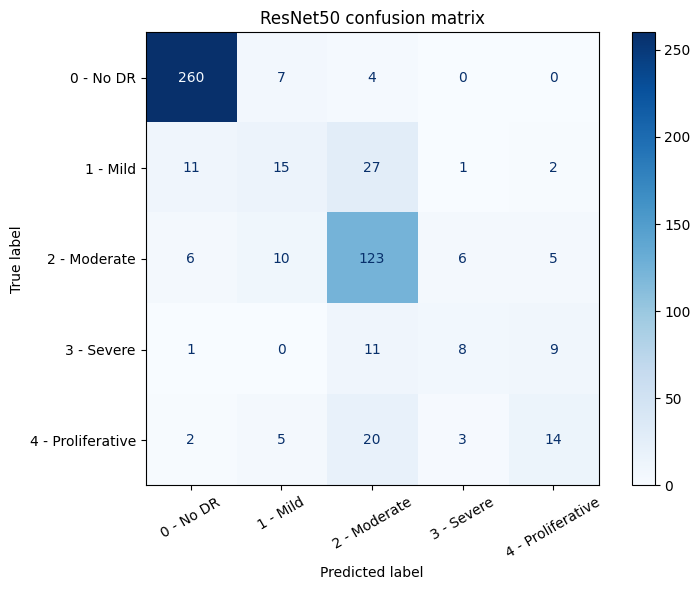

In [1]:
#Reload the saved  model and evaluate it on the held-out test split.
#needed confuson matrix and report (omar amir)
from pathlib import Path
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.applications.resnet50 import preprocess_input

model_candidates = [
    Path('artefacts/ResNet50/resnet50_aptos_complete_model.keras'),
    Path('../artefacts/ResNet50/resnet50_aptos_complete_model.keras'),
]
model_path = next((path.resolve() for path in model_candidates if path.is_file()), None)
if model_path is None:
    raise FileNotFoundError('Could not find artefacts/ResNet50/resnet50_aptos_complete_model.keras.')

split_candidates = [
    Path('datasets/aptos_512_clahe_balanced/test'),
    Path('Dataset/aptos_512_clahe_balanced/test'),
    Path('../datasets/aptos_512_clahe_balanced/test'),
    Path('../Dataset/aptos_512_clahe_balanced/test'),
]
test_root = next((path.resolve() for path in split_candidates if (path / 'labels.csv').is_file()), None)
if test_root is None:
    raise FileNotFoundError('Could not find the balanced test split with labels.csv.')

evaluation_model = tf.keras.models.load_model(model_path, compile=False)
test_labels = pd.read_csv(test_root / 'labels.csv')
required_columns = {'id_code', 'diagnosis'}
if not required_columns.issubset(test_labels.columns):
    raise ValueError(f'Test labels must contain columns: {sorted(required_columns)}')
test_labels['diagnosis'] = test_labels['diagnosis'].astype('int32')
test_labels['image_path'] = test_labels['id_code'].map(
    lambda image_id: str(test_root / 'images' / f'{image_id}.png')
)
missing_images = test_labels.loc[~test_labels['image_path'].map(os.path.isfile), 'image_path']
if not missing_images.empty:
    raise FileNotFoundError(f'Missing test images, for example: {missing_images.iloc[0]}')

image_size = tuple(evaluation_model.input_shape[1:3])
batch_size = 16

def _load_resnet_test_image(path):
    image = tf.io.decode_png(tf.io.read_file(path), channels=3)
    image = tf.image.resize(image, image_size, method='lanczos3')
    image = tf.cast(image, tf.float32)
    return preprocess_input(image)

test_dataset = tf.data.Dataset.from_tensor_slices(test_labels['image_path'].to_numpy(dtype=str))
test_dataset = test_dataset.map(_load_resnet_test_image, num_parallel_calls=tf.data.AUTOTUNE)
test_dataset = test_dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

y_true = test_labels['diagnosis'].to_numpy(dtype=np.int32)
y_pred = evaluation_model.predict(test_dataset, verbose=1).argmax(axis=1)
class_names = ['0 - No DR', '1 - Mild', '2 - Moderate', '3 - Severe', '4 - Proliferative']
labels = list(range(len(class_names)))

print(f'Loaded model: {model_path}')
print(f'Test split: {test_root} ({len(test_labels)} images)')
print('Classification report:')
print(classification_report(
    y_true, y_pred, labels=labels, target_names=class_names, digits=4, zero_division=0,
))

cm = confusion_matrix(y_true, y_pred, labels=labels)
print('Confusion matrix (rows = true, columns = predicted):')
print(cm)
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(
    ax=ax, cmap='Blues', xticks_rotation=30, values_format='d'
)
ax.set_title('ResNet50 confusion matrix')
fig.tight_layout()
confusion_matrix_path = model_path.parent / 'resnet50_confusion_matrix.png'
fig.savefig(confusion_matrix_path, dpi=200, bbox_inches='tight')
print(f'Confusion matrix saved to: {confusion_matrix_path}')
plt.show()


69/69 ━━━━━━━━━━━━━━━━━━━━ 24s 321ms/step
ROC curve saved to: D:\omar\SIC\grad_project\artefacts\ResNet50\resnet50_roc_curve.png


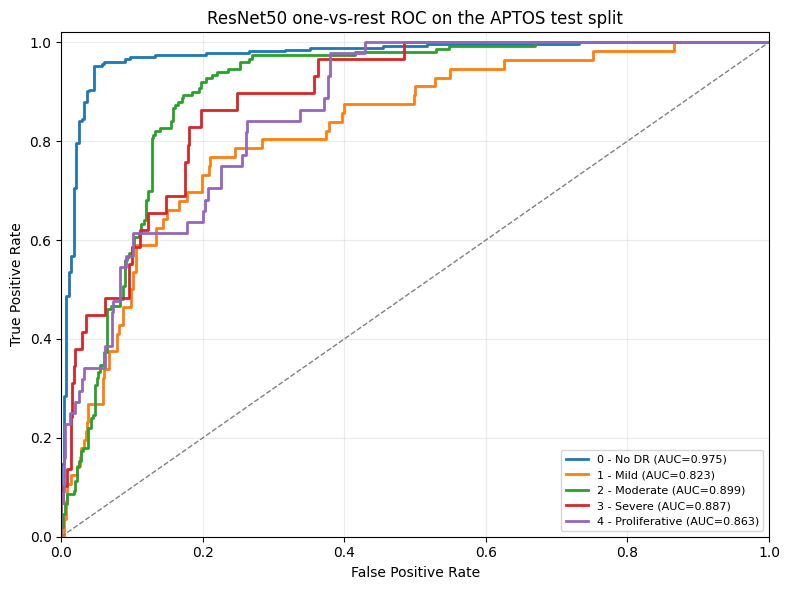

In [2]:
# Reload the saved ResNet50 model and plot its one-vs-rest ROC curves.
from pathlib import Path
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from tensorflow.keras.applications.resnet50 import preprocess_input

model_candidates = [
        Path('artefacts/ResNet50/resnet50_aptos_complete_model.keras'),
        Path('../artefacts/ResNet50/resnet50_aptos_complete_model.keras')
]
roc_model_path = next((p.resolve() for p in model_candidates if p.is_file()), None)
if roc_model_path is None:
    raise FileNotFoundError('Could not find the saved ResNet50 model.')

test_split_candidates = [
    Path('datasets/aptos_512_clahe_balanced/test'),
    Path('Dataset/aptos_512_clahe_balanced/test'),
    Path('../datasets/aptos_512_clahe_balanced/test'),
    Path('../Dataset/aptos_512_clahe_balanced/test'),
]
roc_test_root = next((p.resolve() for p in test_split_candidates if (p / 'labels.csv').is_file()), None)
if roc_test_root is None:
    raise FileNotFoundError('Could not find the balanced test split with labels.csv.')
roc_frame = pd.read_csv(roc_test_root / 'labels.csv')
roc_y_true = roc_frame['diagnosis'].to_numpy(dtype=np.int32)
class_ids = np.arange(5)
roc_y_one_hot = label_binarize(roc_y_true, classes=class_ids)
class_names = ['0 - No DR', '1 - Mild', '2 - Moderate', '3 - Severe', '4 - Proliferative']

roc_model = tf.keras.models.load_model(roc_model_path, compile=False)
input_size = tuple(roc_model.input_shape[1:3])
image_paths = roc_frame['id_code'].map(
    lambda image_id: str(roc_test_root / 'images' / f'{image_id}.png')
).to_numpy(dtype=str)
missing = [p for p in image_paths if not os.path.isfile(p)]
if missing:
    raise FileNotFoundError(f'Missing test image: {missing[0]}')

def _decode_roc_image(path):
    image = tf.io.decode_png(tf.io.read_file(path), channels=3)
    image = tf.image.resize(image, input_size, method='lanczos3')
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    return image

roc_test_ds = (tf.data.Dataset.from_tensor_slices(image_paths)
               .map(_decode_roc_image, num_parallel_calls=tf.data.AUTOTUNE)
               .batch(8).prefetch(tf.data.AUTOTUNE))
roc_scores = roc_model.predict(roc_test_ds, verbose=1)

fig, ax = plt.subplots(figsize=(8, 6))
for class_index, class_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(roc_y_one_hot[:, class_index], roc_scores[:, class_index])
    class_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, linewidth=2, label=f'{class_name} (AUC={class_auc:.3f})')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1)
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel='False Positive Rate', ylabel='True Positive Rate',
       title='ResNet50 one-vs-rest ROC on the APTOS test split')
ax.grid(alpha=0.25)
ax.legend(loc='lower right', fontsize=8)
fig.tight_layout()
roc_output_path = roc_model_path.parent / 'resnet50_roc_curve.png'
fig.savefig(roc_output_path, dpi=200, bbox_inches='tight')
print(f'ROC curve saved to: {roc_output_path}')
plt.show()
